# Avance: más datos, nuevos hallazgos y comparación con un árbol

Este notebook continúa la primera entrega. Resume los avances para exponerlos sin volver a recorrer todo el EDA.

El profesor permite usar una muestra en la revisión y recomienda avanzar al dataset completo. Mantendremos `Fully Paid = 0` y `Charged Off = 1`: usar toda la data significa todos los préstamos **elegibles**, no inventar el resultado de los activos. Los ejemplos multiclase de la sesión no cambian nuestro objetivo binario.

## 1. Cargar los resultados reproducibles

Si no existen, se calculan con las mismas funciones del script. `RECALCULAR = True` vuelve a ejecutar ambos modos. El modo completo utiliza más memoria y tiempo. La primera entrega permanece en su notebook y archivos originales.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

raiz = Path.cwd()
if raiz.name == 'notebooks':
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
from src.avance import ejecutar_avance
from src.evaluate import tabla_metricas

RECALCULAR = False
MODOS = ['muestra', 'completo']
corridas = {}
for modo in MODOS:
    ruta = raiz / 'outputs' / 'avance' / modo / 'metrics.json'
    if RECALCULAR or not ruta.exists():
        ejecutar_avance(modo=modo)
    corridas[modo] = json.loads(ruta.read_text(encoding='utf-8'))


## 2. ¿Cuántos registros usamos ahora?

Se recorre el archivo por bloques de 50 000 filas y se descartan las columnas posteriores al préstamo antes de cargar los predictores. En modo completo no se muestrea. El porcentaje de faltantes que decide las exclusiones se calcula solo con entrenamiento.

Se cargan todos los elegibles, pero solo los anteriores a 2015 entrenan. Los de 2015–2016 validan y los de 2017 en adelante permanecen reservados. No se ha confirmado todavía que esos cortes reproduzcan el conocimiento de los resultados disponible en cada fecha.

In [2]:
filas = []
for modo, corrida in corridas.items():
    a = corrida['auditoria']
    filas.append({'modo': modo, 'filas_archivo': a['filas_fuente'],
                  'elegibles_archivo': a['elegibles_fuente'],
                  'filas_utilizadas': a['filas_utilizadas'],
                  **a['particion'], 'columnas_modelo': a['columnas_modelo']})
display(pd.DataFrame(filas))
assert corridas['completo']['auditoria']['filas_utilizadas'] == corridas['completo']['auditoria']['elegibles_fuente']


,modo,filas_archivo,elegibles_archivo,filas_utilizadas,entrenamiento,validacion,prueba_reservada,columnas_modelo
0,muestra,2260701,1345310,220003,73701,109382,36920,138
1,completo,2260701,1345310,1345310,451059,668640,225611,139


## 3. Nuevo análisis: qué parte de cada año y plazo tiene un resultado utilizable

La tabla y el gráfico utilizan los conteos de **todo el archivo**, no solo la muestra. El porcentaje elegible divide `Fully Paid + Charged Off` entre todos los préstamos con estado de ese año y plazo. Se conservan por separado los conteos de activos, atrasados y otros estados.

Una menor proporción elegible indica que nuestra población seleccionada cubre menos préstamos de ese grupo. No prueba por sí sola un sesgo ni su causa. Los pagos anticipados son posibles incluso en préstamos a 60 meses. No suponemos que el nombre `2018Q4` sea la fecha de actualización de los estados.
Los estados especiales de política crediticia también explican exclusiones, especialmente en años antiguos. Por tanto, porcentaje elegible no equivale exactamente a porcentaje con préstamo finalizado.


,anio,plazo,total_con_estado,elegibles,porcentaje_elegibles,porcentaje_incumplimiento_elegibles
0,2007,36.0,603,251,41.63,17.93
1,2008,36.0,2393,1562,65.27,15.81
2,2009,36.0,5281,4716,89.30,12.60
3,2010,36.0,9156,8466,92.46,9.95
4,2010,60.0,3381,3070,90.80,21.01
5,2011,36.0,14101,14101,100.00,10.63
6,2011,60.0,7620,7620,100.00,23.60
7,2012,36.0,43470,43470,100.00,13.58
8,2012,60.0,9897,9897,100.00,27.70
9,2013,36.0,100422,100422,100.00,12.33


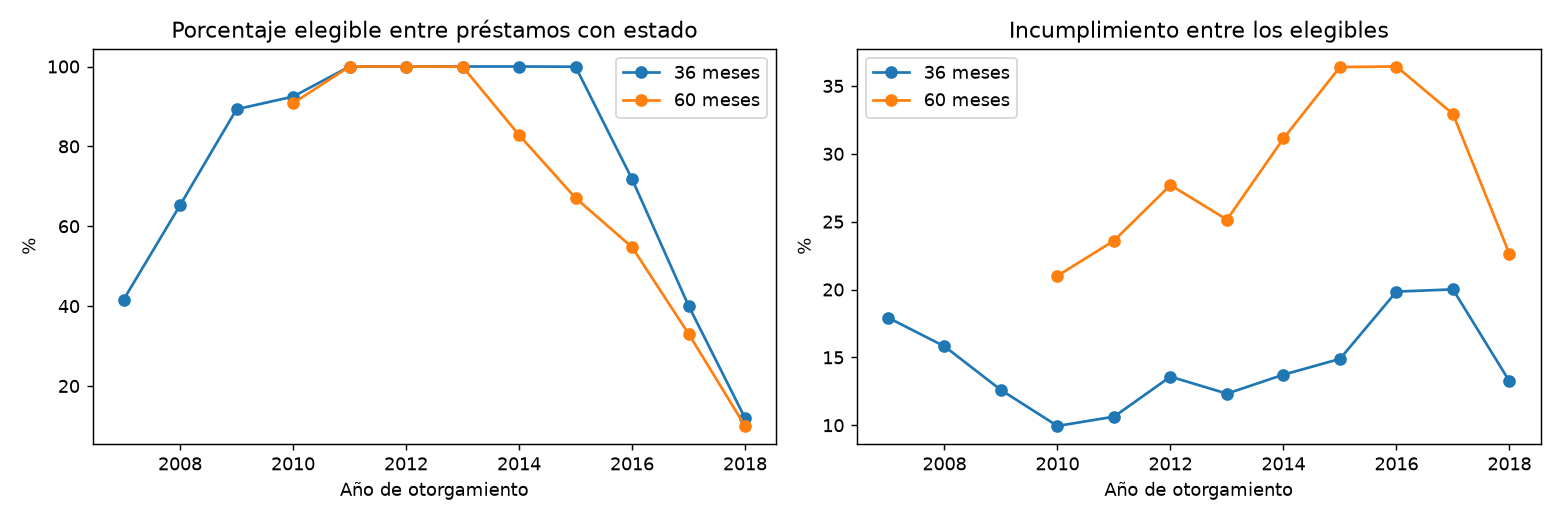

In [3]:
cobertura = pd.read_csv(raiz / 'outputs' / 'avance' / 'completo' / 'cobertura_anio_plazo.csv')
columnas = ['anio', 'plazo', 'total_con_estado', 'elegibles',
            'porcentaje_elegibles', 'porcentaje_incumplimiento_elegibles']
display(cobertura[columnas].round(2))
display(Image(filename=str(raiz / 'reports' / 'figures' / 'avance' / 'completo' / 'cobertura.png')))


## 4. Comparación justa: regresión logística y árbol de decisión

Ambos modelos usan las mismas filas y las mismas variables **sin indicadores ni variables adicionales de LC**, igual que el baseline principal. Se rellena con medianas de entrenamiento, se codifican categorías y se aplica el mismo escalado. El árbol no necesita escalado, pero usarlo permite mantener idéntica la matriz de entrada.

La logística conserva `C=1`, `max_iter=2000`. El árbol toma decisiones mediante reglas sobre las variables; limitamos su profundidad a 6 y exigimos al menos el 0.5 % del entrenamiento por hoja para evitar reglas sustentadas en muy pocos préstamos. Son ajustes iniciales, no el resultado de una búsqueda de hiperparámetros.

Cada umbral maximiza F1 en validación. ROC-AUC es la métrica principal y AP (llamada PR-AUC en la tabla) es la secundaria. Las métricas de clasificación de validación describen también el conjunto usado para elegir ese umbral; no son una evaluación final independiente.

,modo,modelo,conjunto,n,ROC-AUC,PR-AUC,KS,Recall,Precision,F1,Accuracy
0,muestra,logistica_sin_indicadores,entrenamiento,73701,0.7025,0.3234,0.2966,0.6172,0.2773,0.3827,0.6641
1,muestra,logistica_sin_indicadores,validacion,109382,0.7121,0.4016,0.3071,0.6344,0.3440,0.4461,0.6637
2,muestra,arbol_decision,entrenamiento,73701,0.6840,0.3014,0.2684,0.6584,0.2551,0.3678,0.6181
3,muestra,arbol_decision,validacion,109382,0.6717,0.3515,0.2479,0.6450,0.3059,0.4150,0.6119
4,muestra,clase_mayoritaria,entrenamiento,73701,0.5000,0.1687,0.0000,0.0000,0.0000,0.0000,0.8313
5,muestra,clase_mayoritaria,validacion,109382,0.5000,0.2134,0.0000,0.0000,0.0000,0.0000,0.7866
6,completo,logistica_sin_indicadores,entrenamiento,451059,0.7026,0.3240,0.2948,0.6043,0.2832,0.3856,0.6735
7,completo,logistica_sin_indicadores,validacion,668640,0.7156,0.4093,0.3123,0.6265,0.3530,0.4515,0.6721
8,completo,arbol_decision,entrenamiento,451059,0.6772,0.2945,0.2532,0.6561,0.2490,0.3610,0.6061
9,completo,arbol_decision,validacion,668640,0.6797,0.3676,0.2548,0.6733,0.3059,0.4207,0.6005


**Muestra**

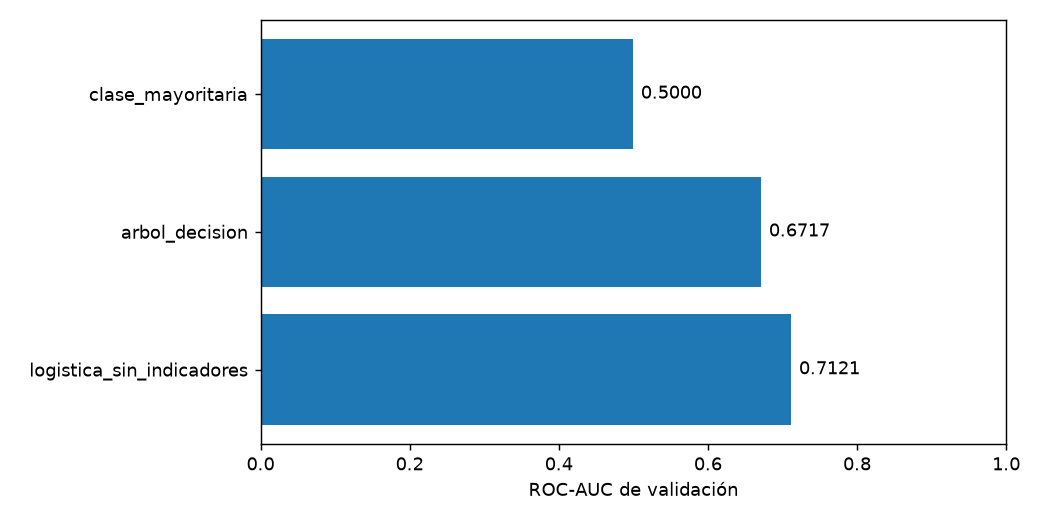

**Completo**

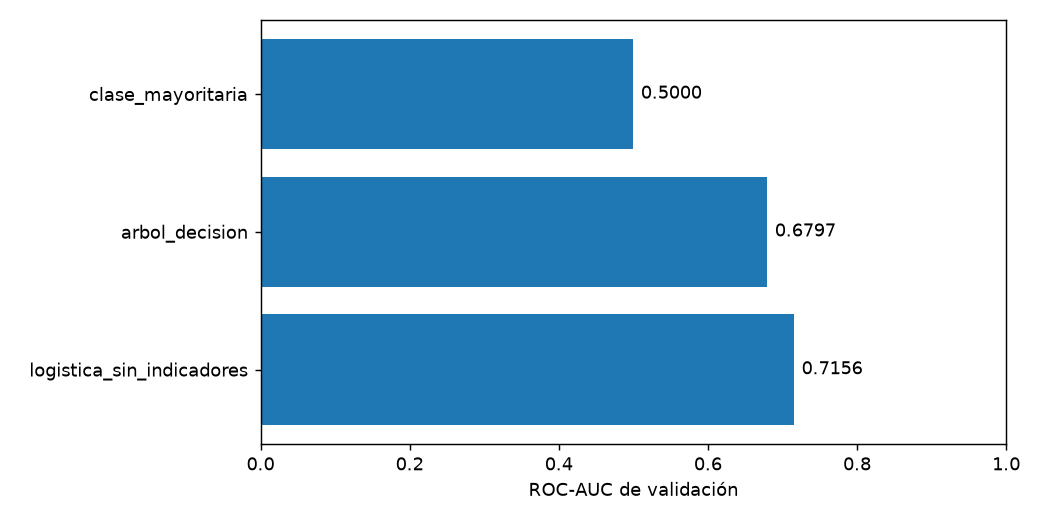

In [4]:
tablas = []
for modo, corrida in corridas.items():
    tabla = tabla_metricas(corrida['resultados'])
    tabla.insert(0, 'modo', modo)
    tablas.append(tabla)
comparacion = pd.concat(tablas, ignore_index=True)
with pd.option_context('display.max_columns', None):
    display(comparacion)
for modo in MODOS:
    display(Markdown('**' + modo.capitalize() + '**'))
    display(Image(filename=str(raiz / 'reports' / 'figures' / 'avance' / modo / 'comparacion.png')))


## 5. Qué aprendimos y qué falta

El nuevo modelo no tiene que ganar: el avance consiste en comprobarlo con evidencia. Comparamos modelos **dentro de cada modo**. Muestra y completo tienen distinta población de validación, así que la diferencia entre modos no aísla el efecto de aumentar el entrenamiento.

No volvemos a evaluar prueba para elegir modelos. Sus resultados de la primera entrega ya fueron consultados y esa limitación permanece documentada.

In [5]:
for modo, corrida in corridas.items():
    r = corrida['resultados']
    base = r['logistica_sin_indicadores']['validacion']['roc_auc']
    arbol = r['arbol_decision']['validacion']['roc_auc']
    print(f'{modo}: ROC-AUC logística = {base:.4f}; árbol = {arbol:.4f}; diferencia árbol - logística = {arbol-base:+.4f}')
    print('Segundos de entrenamiento:', {k: round(v, 2) for k, v in corrida['segundos_entrenamiento'].items()})
    assert not corrida['configuracion']['prueba_evaluada']
    assert all('prueba' not in conjuntos for conjuntos in r.values())


muestra: ROC-AUC logística = 0.7121; árbol = 0.6717; diferencia árbol - logística = -0.0403
Segundos de entrenamiento: {'logistica_sin_indicadores': 1.57, 'arbol_decision': 1.6}
completo: ROC-AUC logística = 0.7156; árbol = 0.6797; diferencia árbol - logística = -0.0359
Segundos de entrenamiento: {'logistica_sin_indicadores': 6.74, 'arbol_decision': 13.86}


## 6. Guion breve para presentar el avance

1. Mostrar cuántos préstamos elegibles se utilizan en cada modo y cómo se leen por bloques.
2. Mostrar la cobertura por año y plazo, diferenciando los resultados observados de las hipótesis sobre seguimiento.
3. Explicar qué hace el árbol y compararlo con la logística en validación.
4. Mostrar si mejora o empeora y cuánto tarda; no prometer que más datos o más complejidad siempre mejoren.
5. Señalar lo pendiente: confirmar la actualización de los estados y disponibilidad histórica del resultado, revisar los cortes y ampliar después la comparación de modelos.

Para reproducir desde consola:

```bash
python -m src.avance --modo muestra
python -m src.avance --modo completo
```

Los resultados del avance se guardan en `outputs/avance/`, separados de los de la primera entrega.